In [2]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns
from PIL import Image

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

from torchvision import datasets
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

from datetime import datetime

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

load_dotenv()
# 오류 발생시
sklearn.set_config(display="text")

[문제 1] 데이터 로드 & 증강 파이프라인 구성 (힌트 제공) (15점)

요구사항

- 입력 크기: 224 x 224

- 배치 크기: 32

- 훈련/검증 분리: 80 / 20

- 훈련(train)에만 증강 적용

- 클래스 수: 본인이 선택한 데이터셋 기준으로 명시 (예: 2진 분류 또는 다중 분류)

In [3]:
base_path = r"C:\kdt_0900_osh\ml\resource\datasets"

In [3]:
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

os.makedirs(base_path, exist_ok=True)
# https://www.kaggle.com/datasets/rm1000/augmented-apple-disease-detection-dataset
api.dataset_download_files(r"rm1000/augmented-apple-disease-detection-dataset", path=base_path, unzip=True)

print("다운로드 완료")

Dataset URL: https://www.kaggle.com/datasets/rm1000/augmented-apple-disease-detection-dataset
다운로드 완료


In [4]:
file_path = os.path.join(base_path, r"apple_disease")
file_path

'C:\\kdt_0900_osh\\ml\\resource\\datasets\\apple_disease'

In [5]:
base_dataset = ImageFolder(file_path, transform=None)

In [7]:
train_subset, temp_subset = train_test_split(base_dataset, test_size=0.2, stratify=base_dataset.targets, random_state=42)
val_subset, test_subset = train_test_split(temp_subset, test_size=0.5, stratify=[i[1] for i in temp_subset], random_state=42)

In [8]:
len(train_subset), len(val_subset), len(test_subset)

(9600, 1200, 1200)

In [9]:
class DatasetWrapper(Dataset):
    def __init__(self, dataset, transform=None):
        self.dataset = dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        x, y = self.dataset[idx]
        if self.transform:
            x = self.transform(x)
        return x, y

In [10]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

In [12]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

test_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [13]:
train_dataset = DatasetWrapper(train_subset, transform=train_transform)
val_dataset = DatasetWrapper(val_subset, transform=test_transform)
test_dataset = DatasetWrapper(test_subset, transform=test_transform)

In [14]:
len(train_dataset), len(val_dataset), len(test_dataset), len(base_dataset)

(9600, 1200, 1200, 12000)

In [15]:
train_dataloader = DataLoader(train_dataset, shuffle=True, batch_size=32)
val_dataloader = DataLoader(val_dataset, shuffle=False, batch_size=32)
test_dataloader = DataLoader(test_dataset, shuffle=False, batch_size=32)

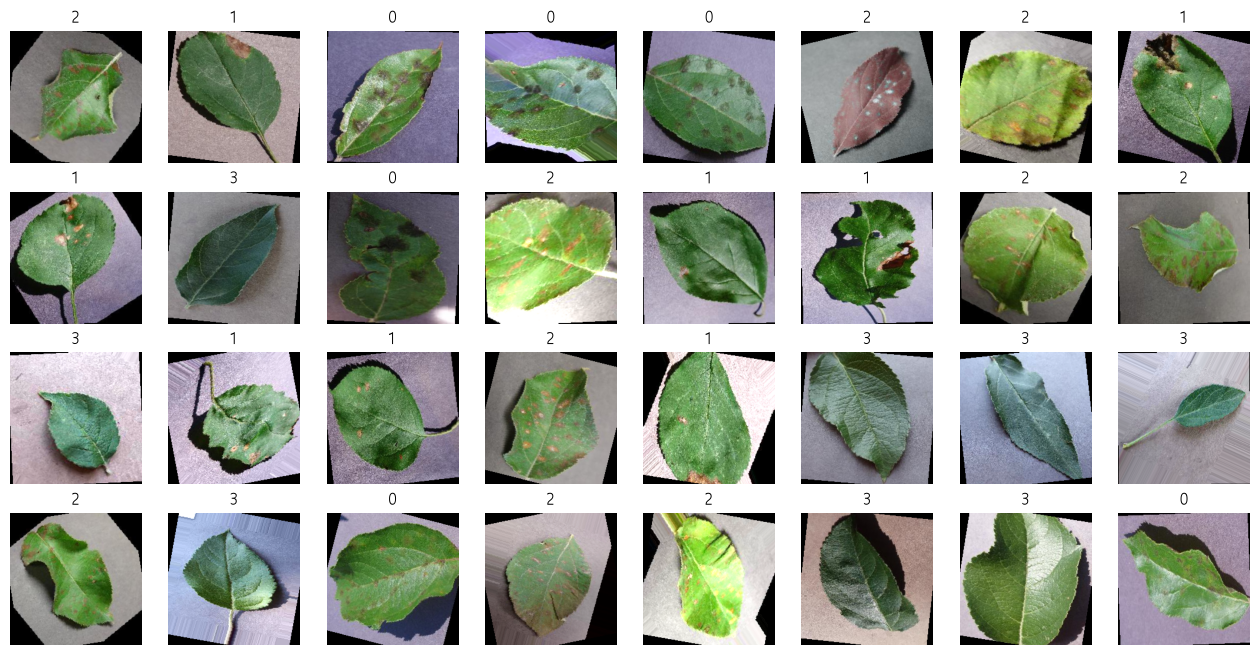

tensor([2, 1, 0, 0, 0, 2, 2, 1, 1, 3, 0, 2, 1, 1, 2, 2, 3, 1, 1, 2, 1, 3, 3, 3,
        2, 3, 0, 2, 2, 3, 3, 0])


In [16]:
imgs, labels = next(iter(train_dataloader))

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for ax, img, label in zip(axes.flatten(), imgs, labels):
    img = img * std + mean
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(label.item())
    ax.axis("off")

plt.show()

[문제 2] 베이스 모델 선택 & 선택 이유(서술) (15점)

요구사항 다음 조건을 만족하도록 베이스 모델 1개를 선택하고, 선택 이유를 8~12줄로 서술하라. 서술 항목(필수 포함)

1. 데이터 특성(클래스 수, 데이터 규모 추정, 난이도, 이미지 특징)

2. 모델 트레이드오프(정확도 vs 속도 vs 모델 크기/파라미터 수)

3. 실행 환경 고려(로컬 GPU/MPS, Colab T4, 학습 시간 등)

4. 위험요소(과적합, 배경 편향, 전처리 호환 등)와 대응 1개

In [17]:
class_dict = dict(enumerate(base_dataset.classes))
class_dict

{0: 'Apple Scab', 1: 'Black Rot', 2: 'Cedar Apple Rust', 3: 'Healthy'}

In [18]:
1280 * 256 * 4

1310720

1. 데이터셋은 'Apple Scab', 'Black Rot', 'Cedar Apple Rust', 'Healthy'의 4개 클래스를 가진다.
   이미지 데이터는 클래스별로 3000개씩 총 12000개 존재한다.
   이미지를 보았을 때 반사광으로 인해 잘 보이지 않는 사진들이 포함되어있긴 하지만 잎의 크기가 비교적 일정하고 잎의 생김세 또한 자세하게 나와있을 뿐 아니라 각 질병과 질병 간, 질병과 정상 간의 차이들도 비교적 뚜렷한 편이므로 난이도가 높지 않을 것으로 예상된다.

2. 해당 데이터셋을 통해 만들어진 모델은 사과나무의 질병 종류 파악이 주 목적이다. 이때 이 모델이 사용될 곳은 사과농장이라는 제한된 장소이다. 때문에 농장에 설치된 기기만으로도 모델을 활용할 수 있도록 모델의 크기를 줄이고 파라미터 수를 낮추는 것이 좋다. 

3. 현재 노트북 실행환경에서는 CUDA Gpu를 사용할 수 있으므로 무거운 모델도 돌릴 수 있지만 실제 농장에서는 하드웨어의 성능이 다를 수 있다는 점을 간과할 수 없다. MobileNetV2는 파라미터의 수가 상대적으로 적어 메모리와 연산의 부담을 줄일 수 있다. 학습 시간은 epoch 10 기준 11분 4초이다.

4. 모델의 크기를 줄여 실행해본 결과 Test Loss: 0.0300, Test Accuracy: 98.93%, Train Loss: 0.0114, Train Accuracy: 99.72%인 것으로 보아 과적합은 발생하지 않았다. 다만 배경이 단색이므로 배경 편향이 발생할 수 있다. 때문에 데이터 증강 과정에서 배경의 변화를 주기 위해 transforms.RandomRotation()을 적용해야한다. 다른 증강의 경우 클래스 구분의 핵심적인 특징인 잎의 점들을 가리거나 변형시킬 수 있어 적용하지 않기로 결정했다.

위의 근거들을 토대로 최종적으로 선택한 모델은 온디바이스 환경에서 실행이 가능한 MobileNet이다.

In [19]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: cuda


[문제 3] 전이학습 모델 구현 & 훈련(Feature Extraction) (40점)

요구사항(공통)

선택한 베이스 모델로 특징추출 전이학습 모델을 구성하고 학습하라.

필수 조건

- 사전 모델 상위 분류기 제거 및 교체

- base model은 동결(requires_grad = False) 유지

- 분류기 헤드(필수):

- nn.AdaptiveAvgPool2d((1, 1)) (GAP 적용)

- nn.Dropout(권장)

- nn.Linear(in_features, num_classes)

- optimizer: Adam, learning_rate=0.001

- 체크포인트:

- 검증 정확도 기준 최고 성능 갱신 시 torch.save로 best 모델 저장

## 선택 모델: MobileNet

In [20]:
model_weights_path = os.path.join(base_path, "weights")
os.makedirs(model_weights_path, exist_ok=True)
torch.hub.set_dir(model_weights_path)

model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
model

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

In [22]:
for param in model.parameters():
    param.requires_grad = False

In [23]:
model.classifier = nn.Sequential(
    nn.Dropout(0.2, inplace=False),
    nn.Linear(1280, 128),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(128, 4)
)

In [24]:
model = model.to(device)

In [28]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=0.001)

In [27]:
def train_model_multiclass(model, model_name, train_loader, val_loader, criterion, optimizer, epochs, device, save_base_dir):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0

    # 학습
    start_time = datetime.now()
    print(f"========================={model_name} 학습 시작 | {start_time:%Y-%m-%d %H:%M:%S} ============================")
    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch_multiclass(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc = evaluate_multiclass(model, val_loader, criterion, device)

        print(f"[Epoch: {epoch + 1}] | Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
        print(f"[Epoch: {epoch + 1}] | Validation Loss: {val_loss:.4f} | Validation Accuracy: {val_acc:.2f}%")

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), os.path.join(save_dir, "best_model.pth"))

    torch.save(model.state_dict(), os.path.join(save_dir, f"last_model_{epochs}.pth"))
    end_time = datetime.now()
    elapsed = end_time - start_time
    print(f"========================={model_name} 학습 종료 | 소요 시간: {elapsed}============================")
    return history

In [26]:
@torch.no_grad()
def evaluate_multiclass(model, dataloader, criterion, device="cpu"):
    model.eval()
    sum_losses = 0.0
    sum_accs = 0.0

    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        y_pred = model(X_batch)
        loss = criterion(y_pred, y_batch)
        sum_losses += loss.item()

        # 다중 클래스 정확도 계산
        y_pred_index = y_pred.argmax(dim=1)
        acc = (y_batch == y_pred_index).float().mean().item() * 100
        sum_accs += acc

    avg_loss = sum_losses / len(dataloader)
    avg_acc = sum_accs / len(dataloader)
    
    return avg_loss, avg_acc

In [76]:
history = train_model_multiclass(
    model=model,
    model_name="Mobilenet-apple",
    train_loader=train_dataloader,
    val_loader=val_dataloader,
    criterion=criterion,
    optimizer=optimizer,
    epochs=10,
    device=device,
    save_base_dir=os.path.join(base_path,"weights")
)

=========================Mobilenet-apple 학습 시작 | 2026-10-15 15:16:34 ============================
[Batch 20/300] Batch Loss: 0.0443, Batch Accuracy: 100.00%
[Batch 40/300] Batch Loss: 0.0231, Batch Accuracy: 100.00%
[Batch 60/300] Batch Loss: 0.0192, Batch Accuracy: 100.00%
[Batch 80/300] Batch Loss: 0.1562, Batch Accuracy: 90.62%
[Batch 100/300] Batch Loss: 0.0198, Batch Accuracy: 100.00%
[Batch 120/300] Batch Loss: 0.0341, Batch Accuracy: 96.88%
[Batch 140/300] Batch Loss: 0.0159, Batch Accuracy: 100.00%
[Batch 160/300] Batch Loss: 0.0836, Batch Accuracy: 93.75%
[Batch 180/300] Batch Loss: 0.0369, Batch Accuracy: 100.00%
[Batch 200/300] Batch Loss: 0.0492, Batch Accuracy: 96.88%
[Batch 220/300] Batch Loss: 0.0078, Batch Accuracy: 100.00%
[Batch 240/300] Batch Loss: 0.0491, Batch Accuracy: 96.88%
[Batch 260/300] Batch Loss: 0.1058, Batch Accuracy: 93.75%
[Batch 280/300] Batch Loss: 0.0471, Batch Accuracy: 96.88%
[Batch 300/300] Batch Loss: 0.0282, Batch Accuracy: 100.00%
[Epoch: 1] | 

In [29]:
best_model_path = os.path.join(base_path, r"weights", r"Mobilenet-apple", r"best_model.pth")
best_model_path

'C:\\kdt_0900_osh\\ml\\resource\\datasets\\weights\\Mobilenet-apple\\best_model.pth'

In [30]:
model.load_state_dict(torch.load(best_model_path))
model = model.to(device)

In [77]:
model.eval()

test_loss, test_acc = evaluate_multiclass(
    model=model,
    dataloader=test_dataloader, 
    criterion=criterion,
    device=device)

print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.2f}")

train_loss, train_acc = evaluate_multiclass(
    model=model,
    dataloader=train_dataloader, 
    criterion=criterion,
    device=device)

print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}")

Test Loss: 0.0300 | Test Accuracy: 98.93
Train Loss: 0.0114 | Train Accuracy: 99.72


[문제 4] 모델 평가 및 측정 리포트 (30점)

요구사항

저장된 best 모델을 불러와 아래 항목을 수행하고 리포트로 작성하라.

필수 항목

1. Accuracy 측정(검증 또는 테스트)

2. 추가 지표 1개 선택(Precision/Recall/F1 중 택1 권장)

3. 혼동행렬(confusion matrix) 생성

4. 오분류 5개 이상 추출

- 각 샘플: 정답 라벨 / 예측 라벨 / 예측 확률(또는 점수) 포함

5. 개선 아이디어 2개 제시(파인튜닝 제외)

- 예: 증강 강화, Dropout 조정, 입력 크기/배치 조정, 데이터 불균형 대응 등

- 왜 도움이 되는지 근거 1줄 포함

In [158]:
@torch.no_grad()
def evaluate_list_multiclass(model, dataloader, device="cpu"):
    model.eval()
    y_true_list = []
    y_pred_list = []
    y_point_list = []

    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        y_point = model(X_batch)
        y_point = torch.softmax(y_point, dim=1)
        y_pred = y_point.argmax(dim=1)
        for i in range(len(y_point)):
            y_point_list.append(dict(enumerate([round(j.item() * 100) for j in y_point[i]])))

        y_true_list += [i.item() for i in y_batch]
        y_pred_list += [i.item() for i in y_pred]

    return y_true_list, y_pred_list, y_point_list


In [159]:
y_true_list, y_pred_list, y_point_list = evaluate_list_multiclass(model, test_dataloader, device)

In [160]:
cm = confusion_matrix(y_true_list, y_pred_list)
cm

array([[295,   2,   0,   3],
       [  0, 299,   0,   1],
       [  0,   0, 300,   0],
       [  3,   2,   0, 295]])

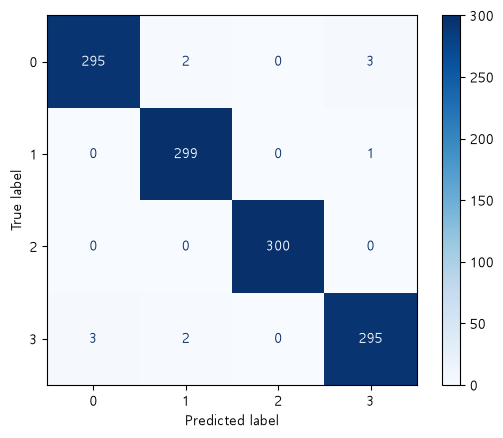

In [161]:
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm)
cm_display.plot(cmap="Blues")
plt.show()

In [162]:
test_image_list = [i[0] for i in test_dataset]

In [163]:
img_true_pred_point_list = list(zip(test_image_list, y_true_list, y_pred_list, y_point_list))
img_true_pred_point_list

[(tensor([[[ 1.4269,  1.3242,  1.3070,  ...,  2.0777,  1.9920,  2.0605],
           [ 1.6495,  1.4783,  1.3242,  ...,  2.0092,  2.0092,  2.0263],
           [ 1.6324,  1.6495,  1.5468,  ...,  1.9920,  2.0777,  2.0092],
           ...,
           [-2.1008, -2.0837, -1.9980,  ...,  1.6667,  1.6324,  1.6667],
           [-2.1008, -1.9980, -2.0152,  ...,  1.6838,  1.6838,  1.6495],
           [-2.0152, -1.9980, -2.0837,  ...,  1.7523,  1.7180,  1.6838]],
  
          [[ 1.4832,  1.3782,  1.3782,  ...,  2.1660,  2.0784,  2.1485],
           [ 1.7283,  1.5532,  1.3957,  ...,  2.1134,  2.1134,  2.1485],
           [ 1.6758,  1.7108,  1.5882,  ...,  2.0784,  2.1660,  2.0959],
           ...,
           [-2.0357, -2.0182, -1.9657,  ...,  1.7283,  1.6758,  1.7108],
           [-2.0357, -1.9657, -1.9832,  ...,  1.7458,  1.7283,  1.6758],
           [-1.9832, -1.9832, -2.0182,  ...,  1.7983,  1.7458,  1.7283]],
  
          [[ 1.6814,  1.5768,  1.5768,  ...,  2.2391,  2.1868,  2.2391],
           

In [164]:
false_img_list = []
for i in img_true_pred_point_list:
    if i[1] != i[2]:
        false_img_list.append(i)

print(false_img_list)

[(tensor([[[0.7762, 0.8104, 0.8104,  ..., 1.2043, 1.1529, 1.0844],
         [0.7591, 0.8104, 0.8104,  ..., 1.1187, 1.0502, 0.9817],
         [0.7591, 0.8104, 0.8104,  ..., 1.0159, 0.9132, 0.7933],
         ...,
         [0.9303, 0.9132, 0.9132,  ..., 0.5022, 0.7933, 0.6734],
         [0.8961, 0.9132, 0.9303,  ..., 0.6392, 0.5707, 0.7933],
         [0.9132, 0.9474, 1.0159,  ..., 0.7933, 0.3652, 0.8961]],

        [[0.5553, 0.5903, 0.5903,  ..., 1.2731, 1.2381, 1.1681],
         [0.5378, 0.5903, 0.5903,  ..., 1.2031, 1.1331, 1.0630],
         [0.5378, 0.5903, 0.6078,  ..., 1.0805, 0.9930, 0.8704],
         ...,
         [0.6604, 0.6429, 0.6429,  ..., 0.5903, 0.8880, 0.7654],
         [0.6429, 0.6429, 0.6604,  ..., 0.7304, 0.6604, 0.8880],
         [0.6604, 0.6954, 0.7654,  ..., 0.8880, 0.4503, 1.0105]],

        [[0.7751, 0.8099, 0.8099,  ..., 1.6814, 1.6465, 1.5768],
         [0.7576, 0.8099, 0.8099,  ..., 1.6117, 1.5245, 1.4548],
         [0.7576, 0.8099, 0.8274,  ..., 1.4722, 1.3851, 

In [ ]:
true_img_list = []
for i in img_true_pred_point_list:
    if i[1] == i[2]:
        true_img_list.append(i)

print(true_img_list)

In [128]:
img_list = [i[0] for i in false_img_list]
true_list = [i[1] for i in false_img_list]
pred_list = [i[2] for i in false_img_list]
point_list = [i[3] for i in false_img_list]

{0: 'Apple Scab', 1: 'Black Rot', 2: 'Cedar Apple Rust', 3: 'Healthy'}


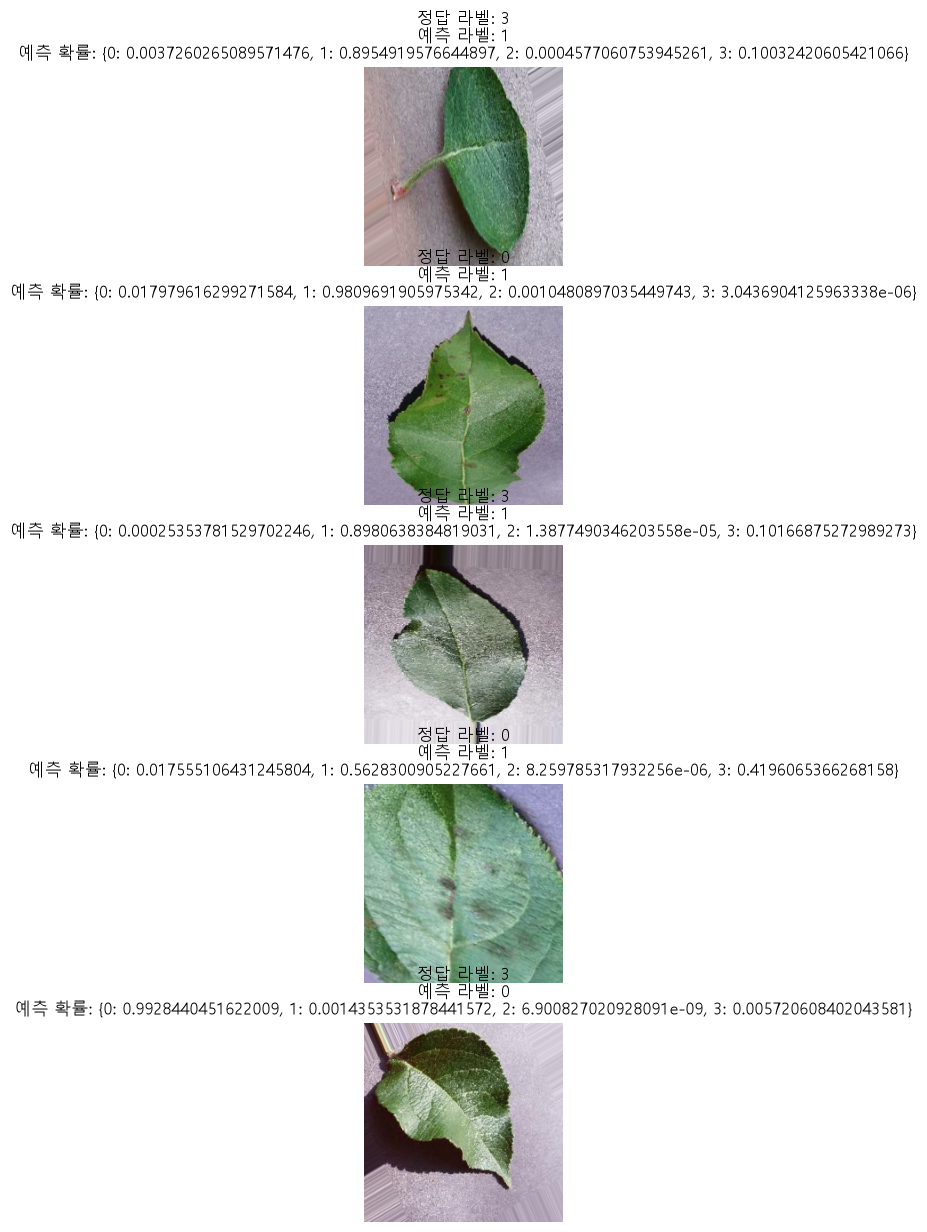

In [136]:
print(class_dict)

imgs, labels = next(iter(test_dataset))

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

fig, axes = plt.subplots(5, 1, figsize=(20, 15))

for ax, img, true, pred, point in zip(axes.flatten(), img_list, true_list, pred_list, point_list):
    img = img * std + mean
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(f"정답 라벨: {true}\n예측 라벨: {pred}\n예측 확률: {point}")
    ax.axis("off")

In [165]:
model

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=